# Сравниваем методы для Out of Distribution Detection, расширенный набор для теста OOD

Здесь сравниваются только 4 модели 
* FBCSP Mahalanobis
* FBCSP LOF cosine
* ACM+TS+PCA Isolation Forest
* ACM+TS One-Class SVM (SGD)

Для теста OOD добавляются дополнительные данные из записей покоя (с открытыми и закрытыми глазами) и с движениями глаз. Считаем, что это тоже OOD.

Только cross-session


In [38]:
import os
from pathlib import Path

DATA_ROOT = Path.home() / "mne_data"
DATA_ROOT.mkdir( parents=True, exist_ok=True )
os.environ.setdefault( "MNE_DATA", str( DATA_ROOT ) )
os.environ.setdefault( "MNE_DATASETS_BNCI_PATH", str( DATA_ROOT ) )
os.environ.setdefault( "MNE_DONTWRITE_HOME", "true" )

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import seaborn as sns

from moabb.datasets import BNCI2014_001
from moabb.pipelines.features import AugmentedDataset
from moabb.pipelines.utils import FilterBank

from pyriemann.estimation import Covariances
from pyriemann.spatialfilters import CSP
from pyriemann.tangentspace import TangentSpace

from scipy.io import loadmat

from sklearn.base import BaseEstimator, clone
from sklearn.covariance import EllipticEnvelope, LedoitWolf
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, StandardScaler, normalize
from sklearn.svm import OneClassSVM, SVC
from sklearn.utils.validation import check_array, check_is_fitted

mne.set_log_level( "WARNING" )

In [39]:
dataset = BNCI2014_001( artifact_handling="ignore" )
ALL_EVENTS = dataset.event_id
ALL_CLASSES = tuple( ALL_EVENTS )
HAND_CLASSES = ( "left_hand", "right_hand" )
HAND_EVENTS = { label: ALL_EVENTS[ label ] for label in HAND_CLASSES }

ALL_DIRECTIONS = [ ( "0train", "1test" ), ( "1test", "0train" ) ]

In [40]:
def prepare_session( runs, event_id, fmin=8, fmax=32 ):
    X, y = [], []
    code_to_label = { code: label for label, code in event_id.items() }

    for run in sorted( runs, key=int ):
        raw = runs[ run ].copy().filter( fmin, fmax, method="iir", picks="data", verbose=False )
        events = mne.find_events( raw, stim_channel="STI", shortest_event=1, verbose=False )
        epochs = mne.Epochs( raw, events, event_id, tmin=2, tmax=6, baseline=None, picks="eeg", proj=False, event_repeated="drop",  verbose=False )
        X.append( epochs.get_data() * dataset.unit_factor )
        y.extend( code_to_label[ code ] for code in epochs.events[ :, 2 ] )

    return np.concatenate( X ), np.array( y )

BANDS = [ ( 8, 12 ), ( 12, 16 ), ( 16, 20 ), ( 20, 24 ), ( 24, 28 ), ( 28, 32 ) ]

def prepare_filterbank( runs, event_id ):
    data = [ prepare_session( runs, event_id, fmin, fmax ) for fmin, fmax in BANDS ]
    return np.stack( [ X for X, _ in data ], axis=-1 ), data[ 0 ][ 1 ]

# adds trials made from open eyes, closed eyes, eyes movements
def prepare_base( subject, runs, prepare ):
    filename = next(
        Path( p ) for p in dataset.data_path( subject )
        if Path( p ).name == f"A{int( subject ):02d}E.mat" # test session
    )
    blocks = loadmat( filename, struct_as_record=False, squeeze_me=True )[ "data" ]
    info = next( iter( runs.values() ) ).info.copy()
    parts = []

    for i, block in enumerate( blocks ):
        if np.size( block.trial ):
            continue

        step = int( 4 * block.fs ) + 1
        stim = np.zeros( len( block.X ) )
        starts = np.arange( 1, len( stim ) - int( 8 * block.fs ), step )
        stim[ starts ] = 99

        raw = mne.io.RawArray( np.vstack( [ block.X.T * 1e-6, stim ] ), info.copy(), verbose=False )
        parts.append( prepare( { "0": raw }, { f"base_{i + 1}": 99 } ) )

    return np.concatenate( [ X for X, _ in parts ] ), np.concatenate( [ y for _, y in parts ] )

def train( train_data, calibration_data, preproc, detector ):
    X_train, y_train = train_data
    X_cal, _ = calibration_data

    fitted_model = make_pipeline( clone( preproc ), clone( detector ) ).fit( X_train, y_train )

    ood_cal = -fitted_model.score_samples( X_cal )
    threshold = np.quantile( ood_cal, 0.95 )

    return fitted_model, threshold, ood_cal

def predict( session, model ):
    X_test, _ = session
    ood_score = -model.score_samples( X_test )
    return ood_score

def evaluate( train_data, calibration_data, test_data, preproc, detector, model_name, subject, known_classes, training_mode ):
    rows, predictions = [], []

    fitted_model, threshold, ood_cal = train( train_data, calibration_data, preproc, detector )
    y_test = test_data[ 1 ]
    ood_score = predict( test_data, fitted_model )
    
    known = np.isin( y_test, known_classes )
    unknown = ~known

    is_reject = ood_score > threshold
    accepted = ~is_reject

    mi_test = known | np.isin( y_test, [ "feet", "tongue" ] )
    base_test = known | np.char.startswith( y_test.astype( str ), "base_" )

    # find best threshold after test (just for info, not used)
    thresholds = np.r_[ np.unique( ood_score )[ ::-1 ], -np.inf ]
    best_threshold = max( thresholds, key=lambda t: accuracy_score( unknown, ood_score > t ) )
    best_reject = ood_score > best_threshold

    info = { 
        "subject": str( subject ), 
        "model": model_name,
        "training_mode": training_mode
    }

    rows.append( {
        **info,
        "n_train": len( train_data[ 1 ] ),
        "n_calibration": len( calibration_data[ 1 ] ),
        "n_test": len( y_test ),
        "n_unknown": int( ( ~known ).sum() ),
        "threshold": threshold,
        "ID_false_reject": is_reject[ known ].mean(),
        "OOD_rejection": is_reject[ unknown ].mean(),
        "OOD_false_accept": accepted[ unknown ].mean(),
        "accepted%": accepted.mean(),
        "OOD_AUROC": roc_auc_score( unknown, ood_score ),
        "OOD_accuracy": accuracy_score( unknown, is_reject ),
        "OOD_accuracy_feet_tongue": accuracy_score( unknown[ mi_test ], is_reject[ mi_test ] ),
        "OOD_accuracy_base": accuracy_score( unknown[ base_test ], is_reject[ base_test ] ),
        "best_threshold": best_threshold,
        "best_cal_percentile": 100 * ( ood_cal <= best_threshold ).mean(),
        "best_OOD_accuracy": accuracy_score( unknown, best_reject ),
        "best_ID_false_reject": best_reject[ known ].mean(),
        "best_OOD_rejection": best_reject[ unknown ].mean(),
    } )

    predictions.append( pd.DataFrame( {
        **info,
        "true_label": y_test,
        "is_known": known,
        "ood_score": ood_score,
        "is_reject": is_reject
    } ) )
    return rows, predictions

In [41]:
HANDS_DIRECTIONS = [ ( "0train", "1test" ) ]

In [42]:

preprocs = {
    "ACM+TS ": make_pipeline(
        AugmentedDataset( order=3, lag=9 ),
        Covariances( estimator="cov" ),
        TangentSpace( metric="riemann" )
    ),
    "ACM+TS+PCA ": make_pipeline(
        AugmentedDataset( order=3, lag=9 ),
        Covariances( estimator="cov" ),
        TangentSpace( metric="riemann" ),
        PCA( n_components=10, svd_solver="full" )
    ),
    "FBCSP ": make_pipeline(
            FilterBank( make_pipeline(
            Covariances( estimator="oas" ),
            CSP( nfilter=8 )
        ) ),
        SelectKBest( mutual_info_classif, k=10 )
    )
}


class KNNDistance( BaseEstimator ):
    def __init__( self, n_neighbors=20 ):
        self.n_neighbors = n_neighbors

    def fit( self, X, y=None ):
        X = check_array( X )
        self.n_features_in_ = X.shape[ 1 ]
        self.neighbors_ = NearestNeighbors( n_neighbors=min( self.n_neighbors, len( X ) ) ).fit( X )
        return self

    def score_samples( self, X ):
        check_is_fitted( self, "neighbors_" )
        X = check_array( X )
        return -self.neighbors_.kneighbors( X )[ 0 ][ :, -1 ]

class ClassMahalanobis( BaseEstimator ):
    def fit( self, X, y ):
        self.classes_, labels = np.unique( y, return_inverse=True )
        self.means_ = np.array( [
            X[ labels == c ].mean( axis=0 )
            for c in range( len( self.classes_ ) )
        ] )
        self.covariance_ = LedoitWolf( assume_centered=True ).fit( X - self.means_[ labels ] )
        return self

    def score_samples( self, X ):
        return -np.min( [
            self.covariance_.mahalanobis( X - mean )
            for mean in self.means_
        ], axis=0 )

detectors = {
    "Robust covariance": EllipticEnvelope(),
    "One-Class SVM": OneClassSVM( kernel="rbf" ),
    "One-Class SVM + scaler":  make_pipeline(
            StandardScaler(),
            OneClassSVM( kernel="rbf" ),
        ),
    "One-Class SVM + norm": make_pipeline(
            Normalizer(),
            OneClassSVM( kernel="rbf" ),
        ),
    "One-Class SVM (SGD)": make_pipeline(
            Nystroem(),
            SGDOneClassSVM(),
        ),
    "Isolation Forest": IsolationForest(), 
    "Local Outlier Factor": LocalOutlierFactor( novelty=True ),
    "LOF cosine": LocalOutlierFactor( metric="cosine", novelty=True ),
    "LOF + norm": make_pipeline(
            Normalizer(),
            LocalOutlierFactor( novelty=True ),
        ),
    "KNN Distance": make_pipeline( 
            Normalizer(), 
            KNNDistance() 
        ),
    "Mahalanobis": make_pipeline( 
            Normalizer(),
            ClassMahalanobis() 
        ),
}

def divide_data( raw_sessions, prepare=prepare_session):
        X, y = prepare( raw_sessions[ "0train" ], HAND_EVENTS )
        X_train, X_cal, y_train, y_cal = train_test_split( X, y, test_size=0.25, stratify=y, random_state=42 )
        train_data = ( X_train, y_train )
        calibration_data = ( X_cal, y_cal )
        test_data = prepare( raw_sessions[ "1test" ], ALL_EVENTS )
        return train_data, calibration_data, test_data

# adds data from other subjects to the train data
def combine_train_data( train_data, subject, prepare ):
    parts = [ train_data ]
    for other_subject in dataset.subject_list:
        if other_subject == subject:
            continue
        sessions = dataset.get_data( subjects=[ other_subject ], n_jobs=1 )[ other_subject ]
        parts.extend( prepare( sessions[ session ], HAND_EVENTS ) for session in ( "0train", "1test" ) )
        del sessions

    return np.concatenate( [ X for X, _ in parts ] ), np.concatenate( [ y for _, y in parts ] )

# makes equal amount of data from each subject (with stratify)
def balance_combined_data( data, n_target ):
    X, y = data
    source = np.arange( n_target, len( y ) )
    source, _ = train_test_split( source, train_size=n_target, stratify=y[ source ] )
    selected = np.r_[ np.arange( n_target ), source ]
    return X[ selected ], y[ selected ]

In [43]:
TRAINING_MODES = [ "cross-session" ] #( "cross-session", "combined" )
all_rows, all_predictions = [], []

tested_combinations = [
    ("FBCSP ", "Mahalanobis"),
    ("FBCSP ", "LOF cosine"),
    ("ACM+TS+PCA ", "Isolation Forest"),
    ("ACM+TS ", "One-Class SVM (SGD)")
]

for pname, dname in tested_combinations:
    preproc = preprocs[ pname ]
    detector = detectors[ dname ]
    prepare = prepare_filterbank if pname.startswith( "FBCSP" ) else prepare_session

    for subject in dataset.subject_list:
        raw_sessions = dataset.get_data( subjects=[ subject ], n_jobs=1 )[ subject ]
        train_data, calibration_data, test_data = divide_data( raw_sessions, prepare )
        X_base, y_base = prepare_base( subject, raw_sessions[ "1test" ], prepare )
        test_data = ( np.concatenate( [ test_data[ 0 ], X_base ] ), np.concatenate( [ test_data[ 1 ], y_base ] ) )
        del raw_sessions

        for training_mode in TRAINING_MODES:
            fit_data = combine_train_data( train_data, subject, prepare ) if training_mode != "cross-session" else train_data
            if training_mode == "combined":
                fit_data = balance_combined_data( fit_data, len( train_data[ 1 ] ) )

            name = pname + dname
            rows, predictions = evaluate( fit_data, calibration_data, test_data,
                preproc, detector, name, subject, HAND_CLASSES, training_mode=training_mode )
            all_rows.extend( rows )
            all_predictions.extend( predictions )
            print( f"{training_mode} | {subject} | {name} -- OOD_AUROC: {rows[ 0 ][ 'OOD_AUROC' ]:.3f} | OOD_accuracy: {rows[ 0 ][ 'OOD_accuracy' ]:.3f}" )

            del fit_data

cross-session | 1 | FBCSP Mahalanobis -- OOD_AUROC: 0.851 | OOD_accuracy: 0.777
cross-session | 2 | FBCSP Mahalanobis -- OOD_AUROC: 0.423 | OOD_accuracy: 0.438
cross-session | 3 | FBCSP Mahalanobis -- OOD_AUROC: 0.893 | OOD_accuracy: 0.814
cross-session | 4 | FBCSP Mahalanobis -- OOD_AUROC: 0.722 | OOD_accuracy: 0.587
cross-session | 5 | FBCSP Mahalanobis -- OOD_AUROC: 0.554 | OOD_accuracy: 0.429
cross-session | 6 | FBCSP Mahalanobis -- OOD_AUROC: 0.646 | OOD_accuracy: 0.524
cross-session | 7 | FBCSP Mahalanobis -- OOD_AUROC: 0.909 | OOD_accuracy: 0.809
cross-session | 8 | FBCSP Mahalanobis -- OOD_AUROC: 0.813 | OOD_accuracy: 0.612
cross-session | 9 | FBCSP Mahalanobis -- OOD_AUROC: 0.803 | OOD_accuracy: 0.613
cross-session | 1 | FBCSP LOF cosine -- OOD_AUROC: 0.864 | OOD_accuracy: 0.792
cross-session | 2 | FBCSP LOF cosine -- OOD_AUROC: 0.416 | OOD_accuracy: 0.458
cross-session | 3 | FBCSP LOF cosine -- OOD_AUROC: 0.899 | OOD_accuracy: 0.826
cross-session | 4 | FBCSP LOF cosine -- OOD

In [44]:
from pathlib import Path
import pandas as pd

notebook = Path( __vsc_ipynb_file__ )
save_dir = notebook.parent / "results"
save_dir.mkdir( exist_ok=True )
results_file = save_dir / f"results_{notebook.stem}.pkl"

pd.to_pickle( { "all_rows": all_rows, "all_predictions": all_predictions }, results_file )
print( results_file )

saved = pd.read_pickle( results_file )
all_rows = saved[ "all_rows" ]
all_predictions = saved[ "all_predictions" ]
results = pd.DataFrame( all_rows )

/Users/liza/Projects/vkr/notebooks/results/results_ood-detection_addldata.pkl


In [45]:
results = pd.DataFrame( all_rows )


## Результаты

* OOD accuracy - для всех OOD
* Feet/tongue - только для MI классов
* Base - для остальных фрагментов (открытые глаза, закрытые, движение глаз)


In [46]:
metrics = [
    "OOD_AUROC",
    "OOD_accuracy",
    "OOD_accuracy_feet_tongue",
    "OOD_accuracy_base",
]

summary = results.groupby( [ "training_mode", "model" ], sort=False )[ metrics ].agg(
    [ "mean", "std" ]
).sort_values( by=( "OOD_AUROC", "mean" ), ascending=False )

display( summary[:5] )

OOD_AUROC           OOD_accuracy  \
                                               mean       std         mean   
training_mode model                                                          
cross-session FBCSP Mahalanobis            0.734961  0.164851     0.622576   
              FBCSP LOF cosine             0.734074  0.173569     0.621405   
              ACM+TS One-Class SVM (SGD)   0.700129  0.167299     0.654864   
              ACM+TS+PCA Isolation Forest  0.683615  0.138341     0.579168   

                                                    OOD_accuracy_feet_tongue  \
                                                std                     mean   
training_mode model                                                            
cross-session FBCSP Mahalanobis            0.148977                 0.650077   
              FBCSP LOF cosine             0.150683                 0.650849   
              ACM+TS One-Class SVM (SGD)   0.074628                 0.579090   
              ACM+TS+PCA Isolation Forest  0.136012                 0.594522   

                                                    OOD_accuracy_base  \
                                                std              mean   
training_mode model                                                     
cross-session FBCSP Mahalanobis            0.133419          0.697840   
              FBCSP LOF cosine             0.140851          0.699087   
              ACM+TS One-Class SVM (SGD)   0.125094          0.493029   
              ACM+TS+PCA Isolation Forest  0.142348          0.685601   

                                                     
                                                std  
training_mode model                                  
cross-session FBCSP Mahalanobis            0.133308  
              FBCSP LOF cosine             0.145318  
              ACM+TS One-Class SVM (SGD)   0.148610  
              ACM+TS+PCA Isolation Forest  0.098602

## Лучшие модели для каждого из участников по AUROC

In [47]:
best = results.sort_values( [ "subject", "OOD_AUROC" ], ascending=[ True, False ] ).groupby( "subject" ).head( 1 )

display( best[ [ "subject", "training_mode", "model", "OOD_AUROC", "OOD_accuracy" ] ] )

,subject,training_mode,model,OOD_AUROC,OOD_accuracy
27,1,cross-session,ACM+TS One-Class SVM (SGD),0.900040,0.823077
19,2,cross-session,ACM+TS+PCA Isolation Forest,0.609131,0.654795
11,3,cross-session,FBCSP LOF cosine,0.898699,0.825714
12,4,cross-session,FBCSP LOF cosine,0.725805,0.584022
4,5,cross-session,FBCSP Mahalanobis,0.554243,0.429319
5,6,cross-session,FBCSP Mahalanobis,0.646236,0.524457
33,7,cross-session,ACM+TS One-Class SVM (SGD),0.920558,0.617021
16,8,cross-session,FBCSP LOF cosine,0.830867,0.619537
17,9,cross-session,FBCSP LOF cosine,0.808000,0.570292


## Лучшие модели для каждого из участников по OOD accuracy

In [48]:
best = results.sort_values( [ "subject", "OOD_accuracy" ], ascending=[ True, False ] ).groupby( "subject" ).head( 1 )

display( best[ [ "subject", "training_mode", "model", "OOD_AUROC", "OOD_accuracy" ] ] )

,subject,training_mode,model,OOD_AUROC,OOD_accuracy
27,1,cross-session,ACM+TS One-Class SVM (SGD),0.900040,0.823077
19,2,cross-session,ACM+TS+PCA Isolation Forest,0.609131,0.654795
11,3,cross-session,FBCSP LOF cosine,0.898699,0.825714
30,4,cross-session,ACM+TS One-Class SVM (SGD),0.688864,0.603306
31,5,cross-session,ACM+TS One-Class SVM (SGD),0.400327,0.623037
32,6,cross-session,ACM+TS One-Class SVM (SGD),0.600756,0.600543
6,7,cross-session,FBCSP Mahalanobis,0.908555,0.808511
34,8,cross-session,ACM+TS One-Class SVM (SGD),0.681916,0.629820
35,9,cross-session,ACM+TS One-Class SVM (SGD),0.741178,0.665782


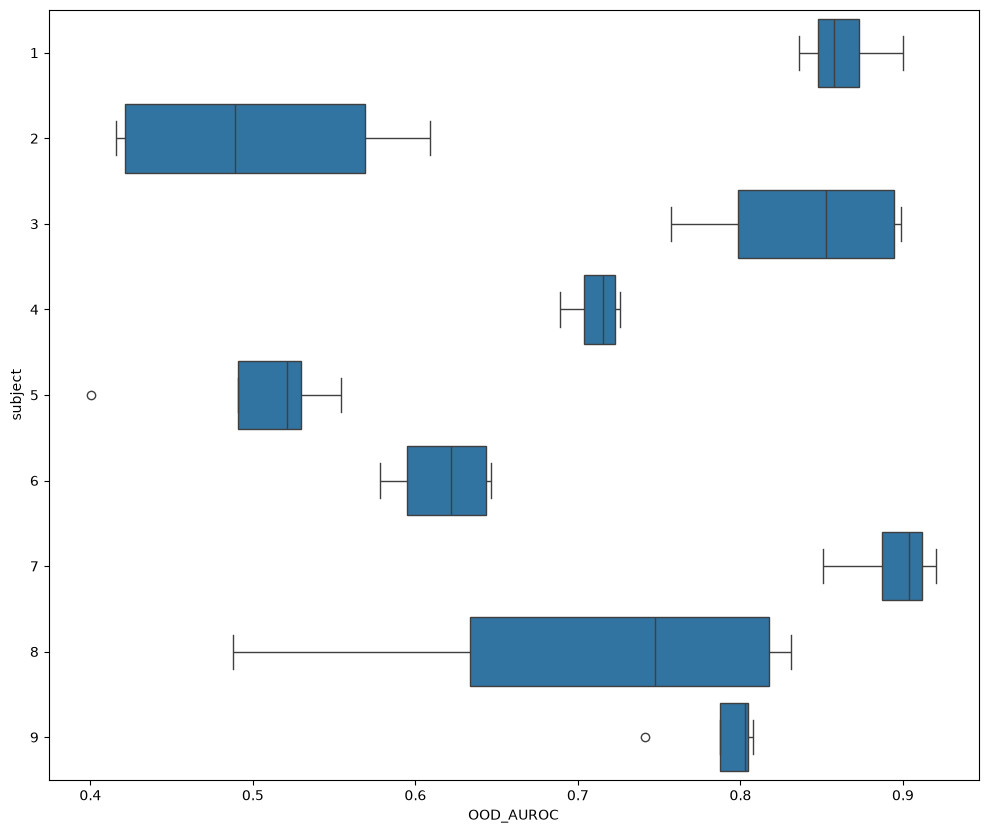

In [58]:
plt.figure( figsize=(12, 10) )
sns.boxplot( data=results, x="OOD_AUROC", y="subject" )
plt.show()

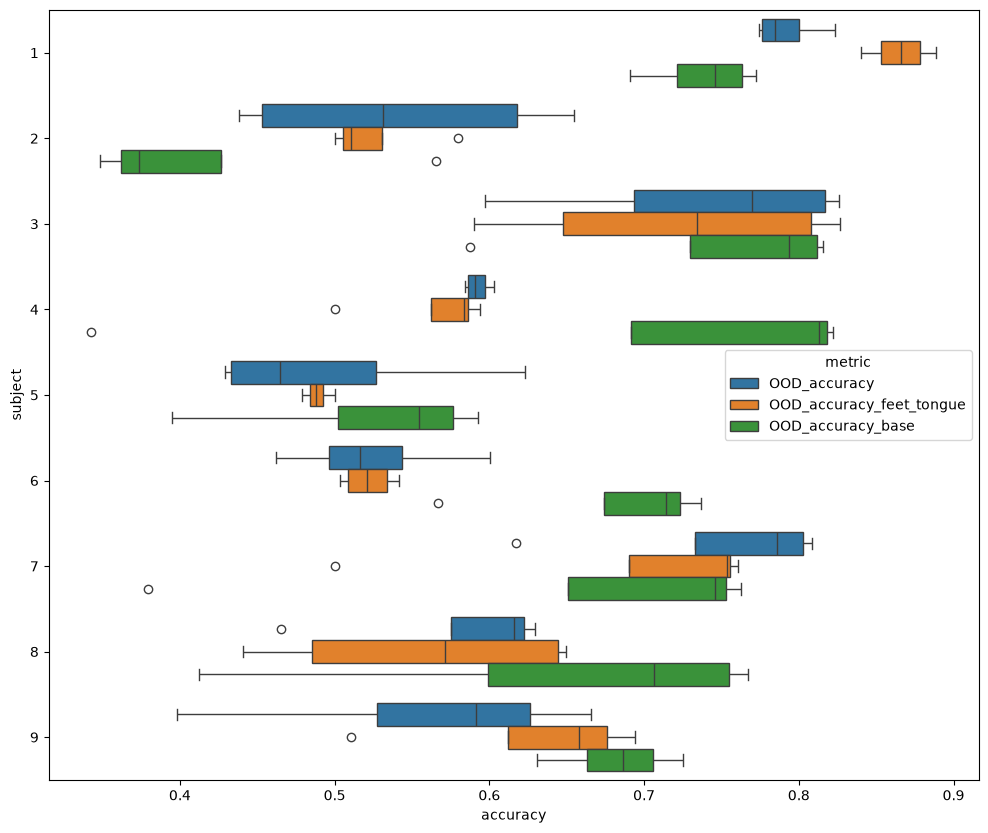

In [59]:
metrics = [ "OOD_accuracy", "OOD_accuracy_feet_tongue", "OOD_accuracy_base" ]

plot_data = results.melt( id_vars="subject", value_vars=metrics, var_name="metric", value_name="accuracy" )

plt.figure( figsize=(12, 10) )
sns.boxplot(  data=plot_data, x="accuracy", y="subject", hue="metric")
plt.show()

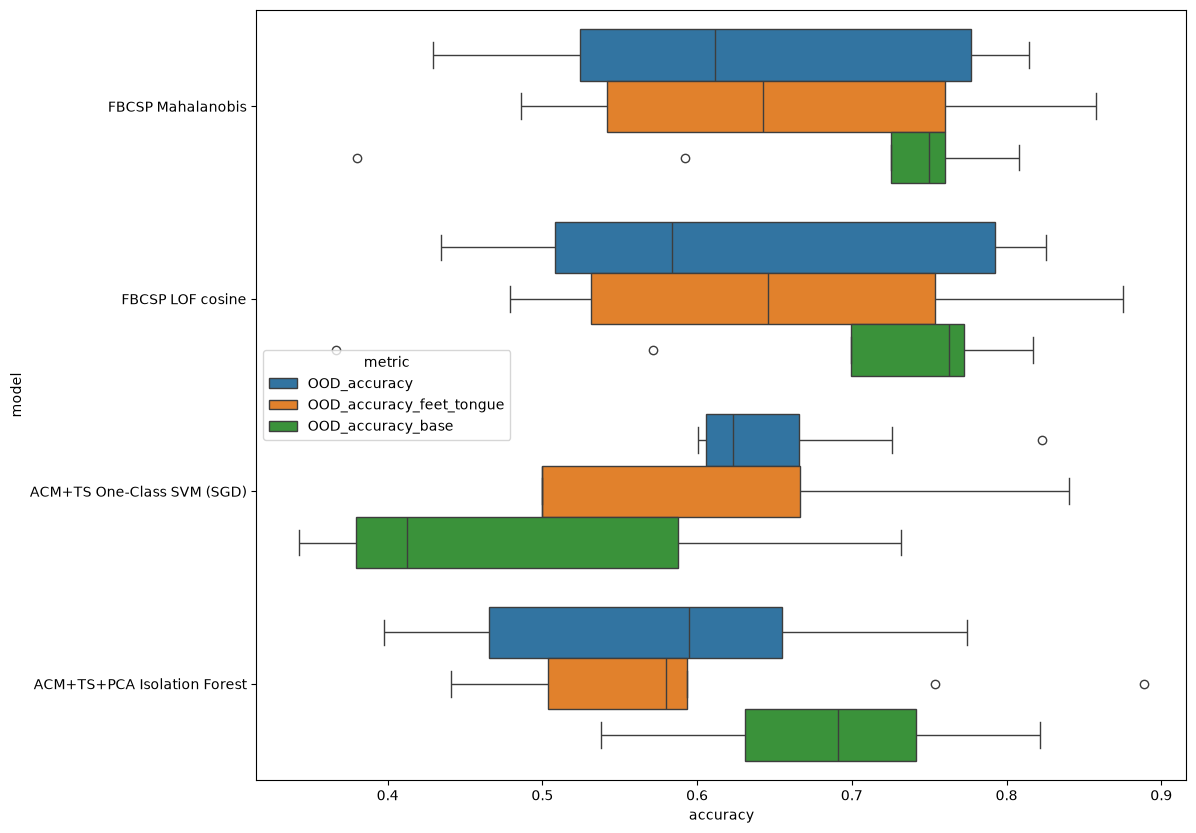

In [51]:
metrics = [ "OOD_accuracy", "OOD_accuracy_feet_tongue", "OOD_accuracy_base" ]

plot_data = results.melt( id_vars="model", value_vars=metrics, var_name="metric", value_name="accuracy" )
order = results.groupby( "model" )[ "OOD_AUROC" ].mean().sort_values( ascending=False ).index

plt.figure( figsize=(12, 10) )
sns.boxplot(  data=plot_data, x="accuracy", y="model", hue="metric", order=order)
plt.show()